# 2D mode fidelity across frequency windows

By default, Run All displays the bundled corrected and uncorrected CSV curves. Set RUN_SIMULATIONS=True to recompute the selected series. Geometry 5, target profile 1 and their calibrated parameters are bundled. Mode fidelity measures overlap with the incident packet; it is not the forward photon population.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


# Mode fidelity vs Frequency Window

Pilot notebook for the 2D experiment. One call writes 3 x 4 CSV files; running the uncorrected and corrected calls writes 24 files in total.

In [1]:
RUN_SIMULATIONS = False  # True recomputes the selected scan and writes its CSVs.
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

resol = 300
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


from importlib import import_module
run_mode_fidelity_vs_freqwindow = import_module("2d_setup.scripts_experiments.mode_fidelity_vs_freqwindow").run_mode_fidelity_vs_freqwindow
load_geometry_by_id = import_module("2d_setup.geometry").load_geometry_by_id

pi = np.pi


In [2]:
geometry_id = 5
id_target_profile = 1
geometry = load_geometry_by_id(geometry_id)

N_A = geometry["N_A"]
Omega_A = 10 * pi * np.ones(N_A)
d_A = np.ones(N_A, dtype=float)

param_atom = {
    "Omega_A": Omega_A,
    "d_A": d_A,
    "geometry": geometry,
    "id_target_profile": id_target_profile,
}

param_photon_bis = {
    "sigma_p": [pi, pi],
    "x_init": [-geometry["lengths"][0] / 4, 0.0],
}
param_time_evol = {"T": geometry["lengths"][0] / 2, "dt": 0.01}

omega_init_values = pi * np.array([10.0, 9.0, 8.0])
cutoffs_list = [
    {"Omega_min": 0 * pi, "Omega_max": 20 * pi},
    {"Omega_min": 1 * pi, "Omega_max": 18 * pi},
    {"Omega_min": 2 * pi, "Omega_max": 16 * pi},
    {"Omega_min": 5 * pi, "Omega_max": 14 * pi},
]

correction = True


Run the experiment

In [3]:
if RUN_SIMULATIONS:
    final_fidelity, paths = run_mode_fidelity_vs_freqwindow(
        param_photon_bis=param_photon_bis,
        param_atom=param_atom,
        param_time_evol=param_time_evol,
        omega_init_values=omega_init_values,
        cutoffs_list=cutoffs_list,
        apply_correction=correction,
        store_results=True,
        progress=True,
    )

    final_fidelity
else:
    print("Using the existing corrected and uncorrected CSV curves.")


Using the existing corrected and uncorrected CSV curves.


<h1> Final values </h1>

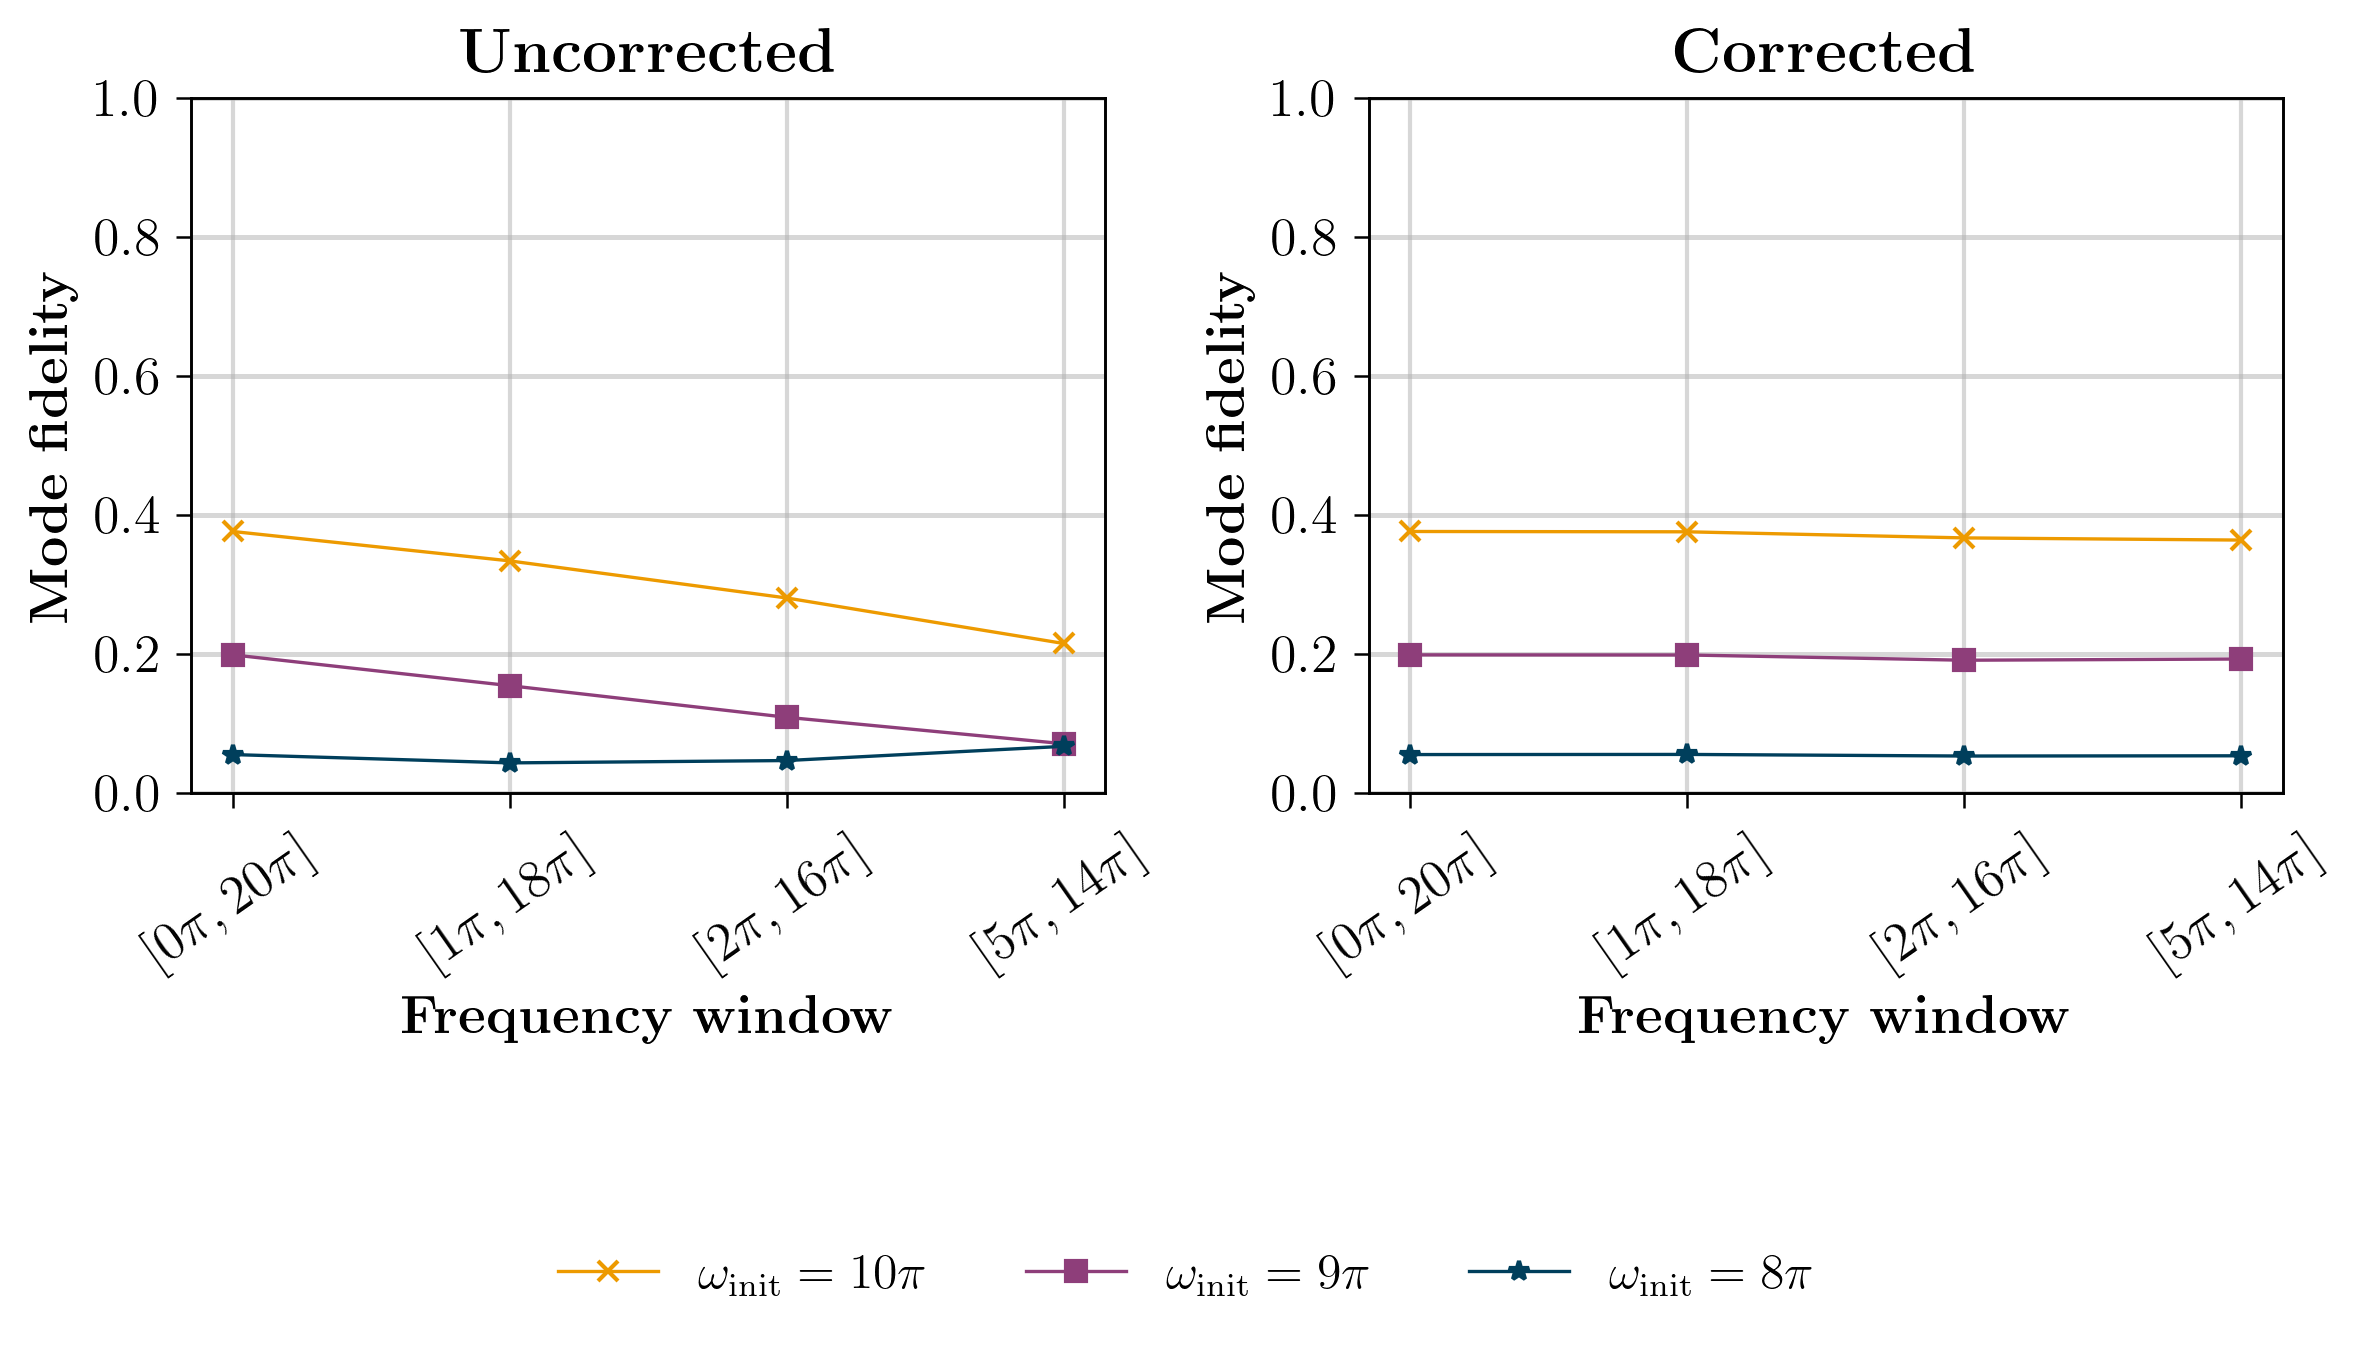

In [4]:
results_dir = setup_root / "results" / "csv_files" / "mode_fidelity_vs_freqwindow"
window_labels = [
    rf"$[{c['Omega_min'] / pi:.0f}\pi,{c['Omega_max'] / pi:.0f}\pi]$"
    for c in cutoffs_list
]
omega_labels = [rf"$\omega_{{\rm init}} = {omega / pi:.0f}\pi$" for omega in omega_init_values]
omega_colors = ["#ed9a00", "#8e3e7a", "#003f5c"]
omega_markers = ["x", "s", "*"]


def mode_fidelity_file(index_omegainit, index_xp, correction):
    suffix = "corrected" if correction else "uncorrected"
    return results_dir / (
        f"mode_fidelity_vs_freqwindow_omegainit_{index_omegainit}"
        f"_xp_{index_xp}_{suffix}.csv"
    )


def final_values(correction):
    values = np.zeros((len(omega_init_values), len(cutoffs_list)))
    for i in range(len(omega_init_values)):
        for j in range(len(cutoffs_list)):
            df = pd.read_csv(mode_fidelity_file(i + 1, j + 1, correction), comment="#")
            values[i, j] = df["mode_fidelity"].iloc[-1]
    return values

fidelity_uncorrected = final_values(False)
fidelity_corrected = final_values(True)
x = np.arange(len(window_labels))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), dpi=resol)

for ax, values, title in zip(
    axes,
    [fidelity_uncorrected, fidelity_corrected],
    [r"\textbf{Uncorrected}", r"\textbf{Corrected}"],
):
    for i, (label, color, marker) in enumerate(zip(omega_labels, omega_colors, omega_markers)):
        ax.plot(
            x,
            values[i],
            marker=marker,
            label=label,
            color=color,
            linewidth=0.8,
            markersize=5,
        )

    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xticks(x, window_labels, rotation=35)
    ax.set_xlabel(r"\textbf{Frequency window}")
    ax.set_ylabel(r"\textbf{Mode fidelity}")
    ax.set_ylim([0, 1])
    ax.grid(which="major", linestyle="-", linewidth=1.2, alpha=0.5)
    ax.grid(axis="x", which="major", linestyle="-", linewidth=1.0, alpha=0.5)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=3,
    frameon=False,
    fontsize=12,
)

for ax in axes:
    for item in [ax.xaxis.label, ax.yaxis.label]:
        item.set_fontsize(13)
    for item in (ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontsize(13)

plt.tight_layout(rect=(0, 0.08, 1, 1))
if SAVE_FIGURES:
    plt.savefig(str(setup_root / "results" / "fig" / f"final_mode_fidelity_vs_freqwindow_2d.pdf"), dpi=resol)
plt.show()


<h1> Visualize the whole evolution </h1>

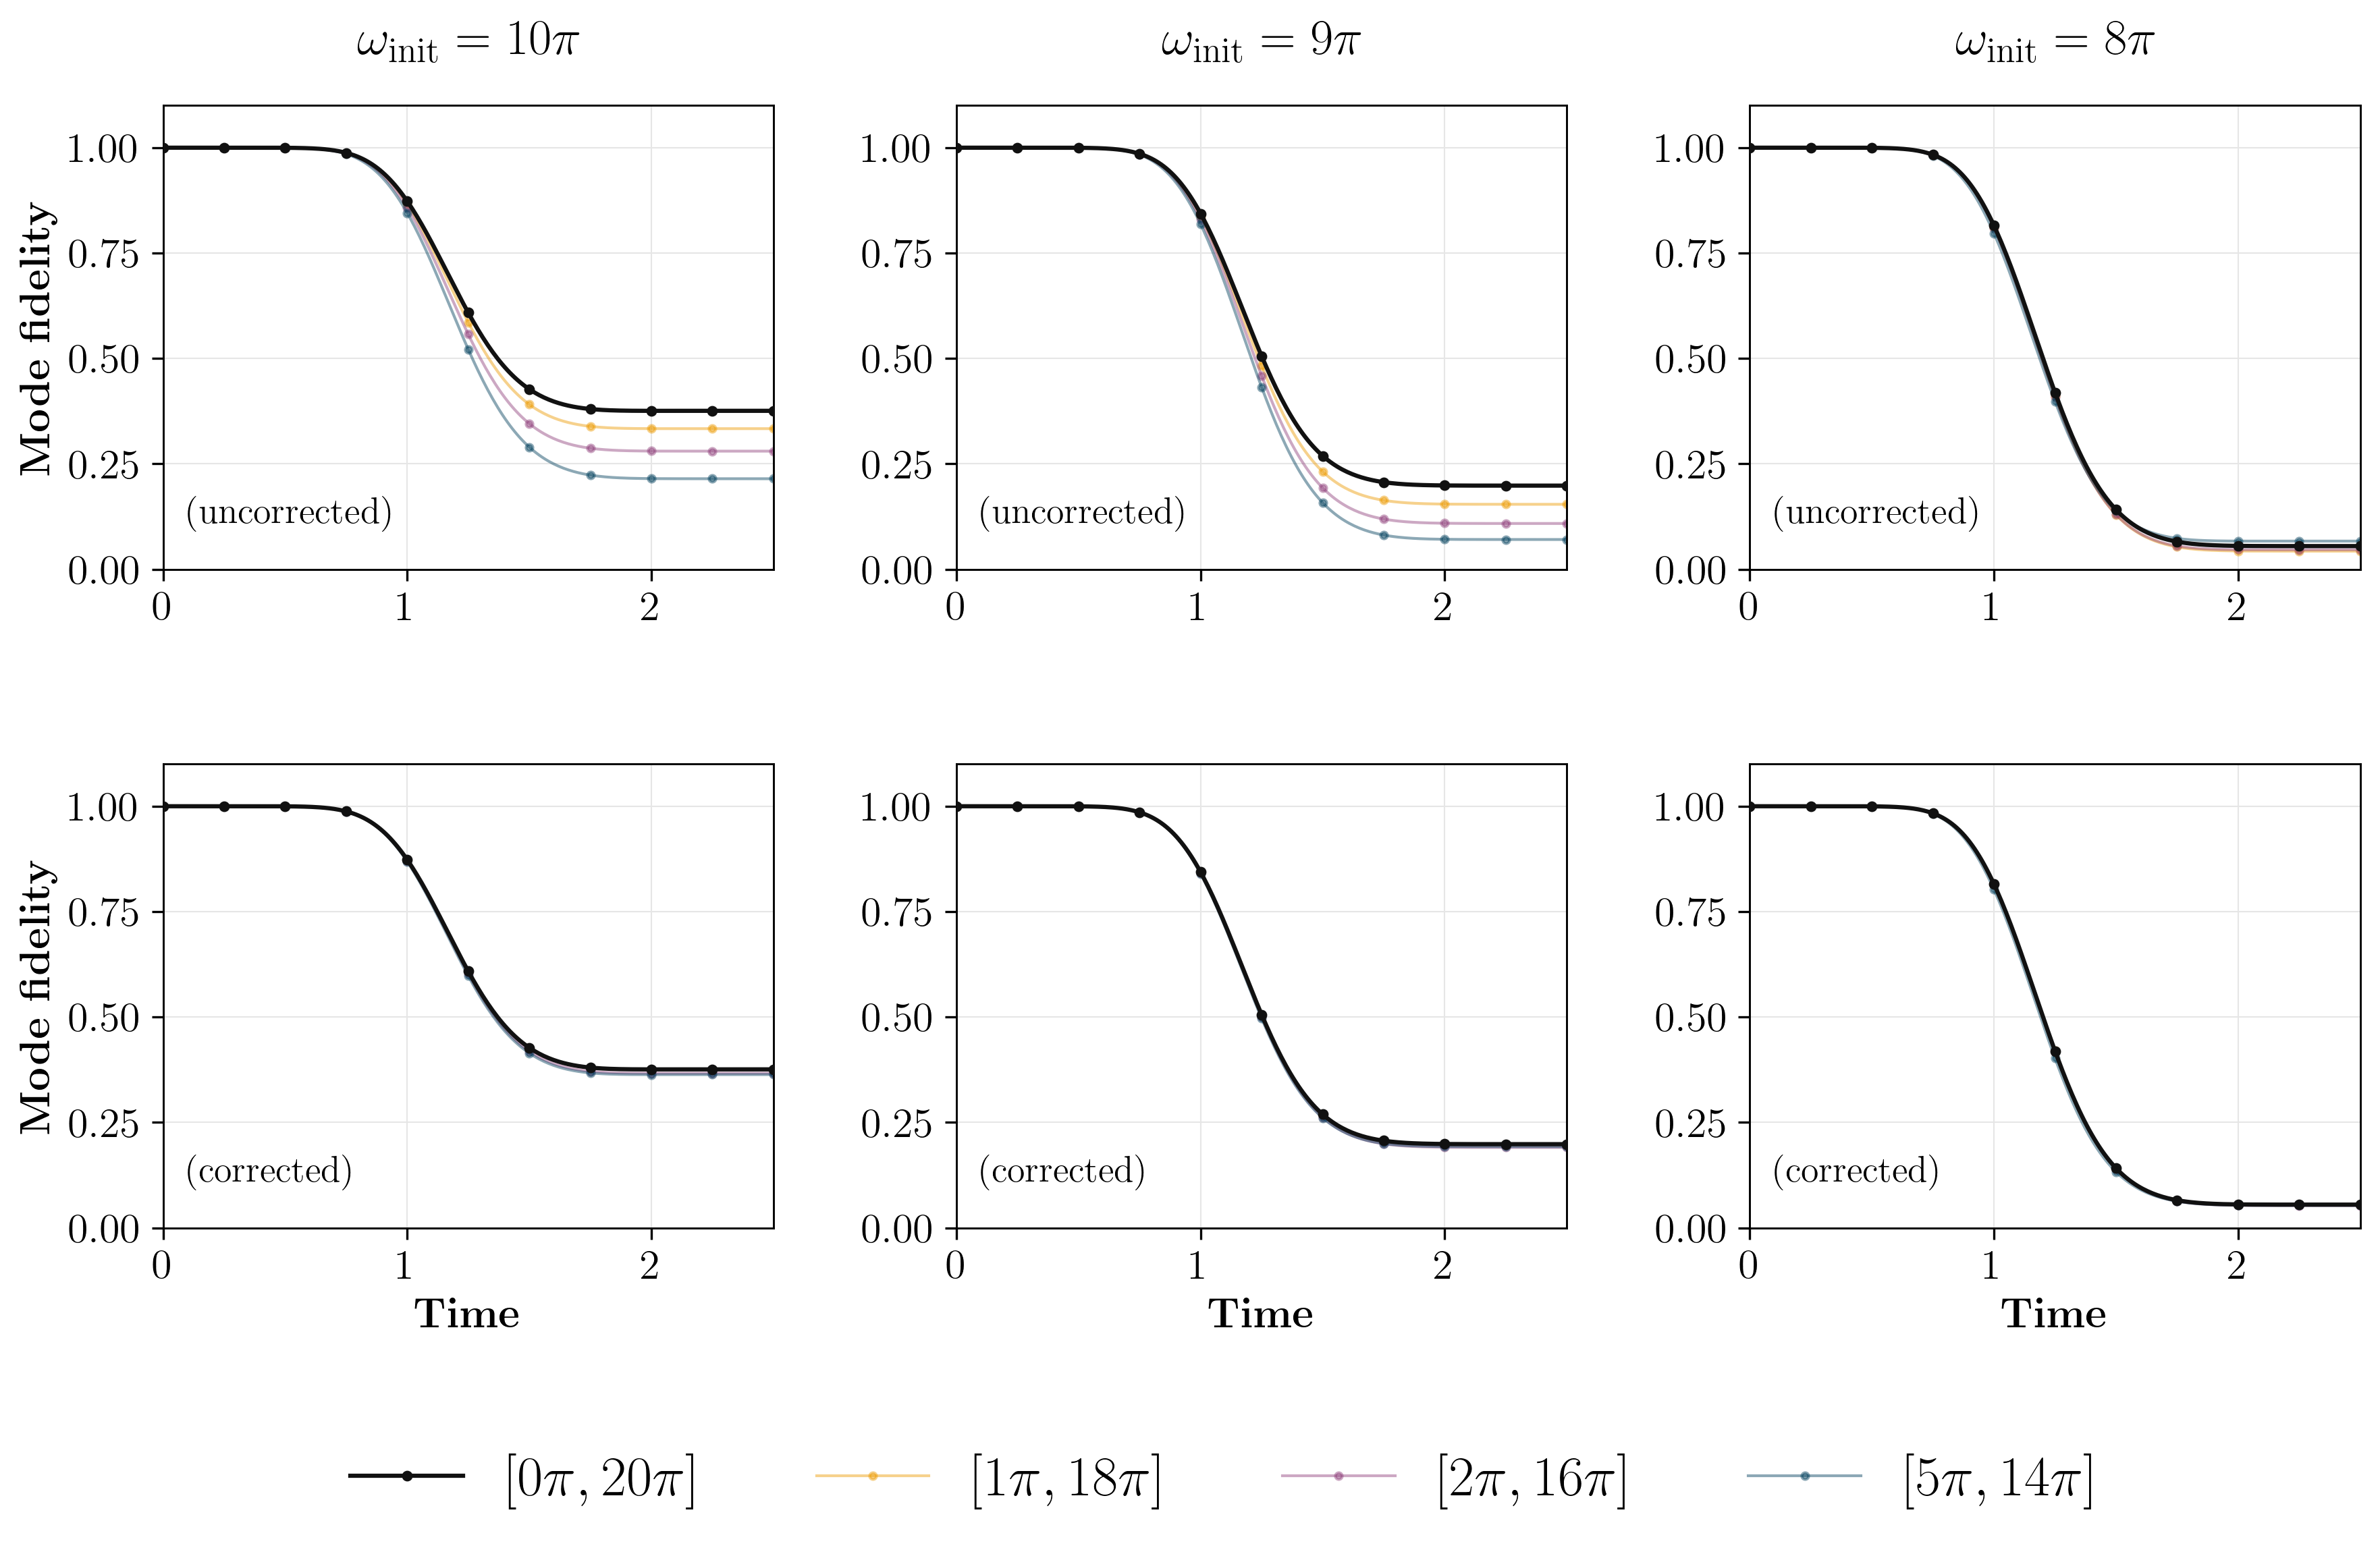

In [5]:
marker_step = 25

window_colors = ["#111111", "#ed9a00", "#8e3e7a", "#003f5c"]
window_alpha = [1.0, 0.45, 0.45, 0.45]
window_lw = [1.5, 1.0, 1.0, 1.0]
window_markers = ["o", "o", "o", "o"]

row_labels = ["(uncorrected)", "(corrected)"]

fig, axs = plt.subplots(2, 3, figsize=(14, 7.2), dpi=resol)
fig.subplots_adjust(wspace=0.3, hspace=0.42)

for row, correction in enumerate([False, True]):
    for col in range(3):
        ax = axs[row, col]
        index_omegainit = col + 1

        for index_xp, (window_label, color, alpha, lw, marker) in enumerate(
            zip(window_labels, window_colors, window_alpha, window_lw, window_markers),
            start=1,
        ):
            df = pd.read_csv(mode_fidelity_file(index_omegainit, index_xp, correction), comment="#")
            time = df["time"].to_numpy()
            mode_fidelity = df["mode_fidelity"].to_numpy()
            ax.plot(
                time,
                mode_fidelity,
                marker=marker,
                markevery=marker_step,
                markersize=2.8 if index_xp == 1 else 2.4,
                label=window_label,
                color=color,
                linewidth=lw,
                alpha=alpha,
                zorder=3 if index_xp == 1 else 2,
            )

        ax.text(
            0.04,
            0.08,
            row_labels[row],
            transform=ax.transAxes,
            fontsize=13,
            fontweight="bold",
            va="bottom",
            ha="left",
        )
        if row == 0:
            ax.set_title(omega_labels[col], fontsize=18, fontweight="bold", pad=18)
        ax.grid(color="0.9", linestyle="-", linewidth=0.5)
        ax.tick_params(axis="both", which="major", length=4, width=0.8, labelsize=15)
        ax.set_xlim([0, param_time_evol["T"]])
        ax.set_ylim([0, 1.1])

for ax in axs[1, :]:
    ax.set_xlabel(r"\textbf{Time}", fontsize=15)
for ax in axs[:, 0]:
    ax.set_ylabel(r"\textbf{Mode fidelity}", fontsize=15)

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=4,
    frameon=False,
    fontsize=20,
)

if SAVE_FIGURES:
    plt.savefig(
        str(setup_root / "results" / "fig" / "timedep_mode_fidelity_vs_freqwindow_2d.pdf"),
        dpi=resol,
        bbox_inches="tight",
    )
plt.show()
